# 02. Data Cleaning & Preprocessing
Guideline section **IV (Data preprocessing)**: missing values, outliers (two detection methods + handling), leakage removal, feature engineering, scaling and encoding.

The cleaning decisions are the ones the team made in the original version of this notebook; this version adds the missing-value audit for every attribute, the outlier analysis and the scaling/encoding documentation.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
import joblib
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

output_dir = '../results/02_data_preprocessing' if os.path.exists('../results') else 'results/02_data_preprocessing'
models_dir = '../models' if os.path.exists('../models') else 'models'
processed_dir = '../data/processed' if os.path.exists('../data') else 'data/processed'
for d in (output_dir, models_dir, processed_dir):
    os.makedirs(d, exist_ok=True)

data_path = '../data/raw/hotel_bookings.csv' if os.path.exists('../data/raw') else 'data/raw/hotel_bookings.csv'
df = pd.read_csv(data_path)
raw = df.copy()
print(f'Starting with {len(df):,} raw records.')

Starting with 119,390 raw records.


## 1. Missing values - percentage for every attribute

,Data type,Missing rows,Missing %
company,float64,112593,94.307
agent,float64,16340,13.686
country,str,488,0.409
children,float64,4,0.003
arrival_date_month,str,0,0.000
arrival_date_week_number,int64,0,0.000
hotel,str,0,0.000
is_canceled,int64,0,0.000
stays_in_weekend_nights,int64,0,0.000
arrival_date_day_of_month,int64,0,0.000


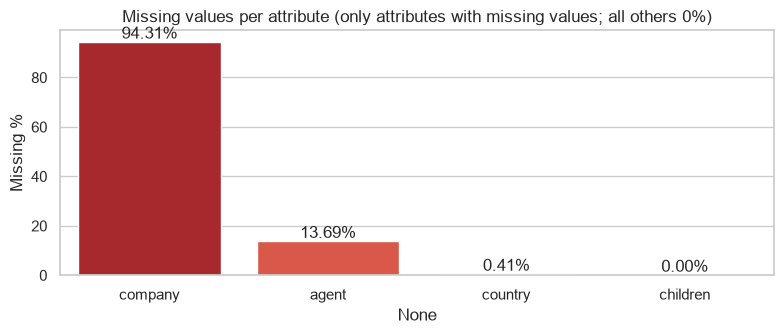

In [2]:
mv = pd.DataFrame({'Data type': df.dtypes.astype(str), 'Missing rows': df.isnull().sum(),
                   'Missing %': (df.isnull().mean() * 100).round(3)}).sort_values('Missing rows', ascending=False)
mv.to_csv(f'{output_dir}/missing_values_all_attributes.csv')
display(mv)

m = mv[mv['Missing rows'] > 0]
plt.figure(figsize=(8, 3.5))
ax = sns.barplot(x=m.index, y=m['Missing %'], hue=m.index, palette='Reds_r', legend=False)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.title('Missing values per attribute (only attributes with missing values; all others 0%)')
plt.ylabel('Missing %')
plt.tight_layout()
plt.savefig(f'{output_dir}/missing_values_bar.png', dpi=300)
plt.show()

### How we handle the missing values and why
Only 4 of the 32 attributes have missing values; the other 28 are complete (0%).

| Attribute | Missing | Our action | Reason |
|---|---|---|---|
| `company` | 94.31% | fill with **0** | NaN means *no company paid* - the absence is information, not an error. Dropping the rows would delete 94% of the data. |
| `agent` | 13.69% | fill with **0** | NaN means *booked without a travel agency* (direct booking). |
| `country` | 0.41% | fill with **'Unknown'** | Origin not recorded; a separate category keeps the 488 rows. |
| `children` | 4 rows | fill with **0** | The mode; 4 rows cannot change the distribution. |

**What would happen if we did not handle them?**
* scikit-learn models (KNN, MLP, Random Forest, Decision Tree in older versions, StandardScaler, PCA) **raise an error** on NaN, so the pipeline would simply not run.
* Dropping every row with a NaN (`dropna`) would delete **~94% of the bookings** because of `company`, leaving a small and biased sample (only company bookings).
* Filling with the mean would be wrong for `agent`/`company` because they are IDs, and it would hide the useful fact that the booking was made directly / privately.
* `total_guests` would be NaN for the 4 rows with missing `children`, so the engineered features would also be broken.

## 2. Remove impossible records (team decision)
- 180 *ghost bookings* with 0 adults, 0 children and 0 babies.
- ADR (price) errors: the negative price and the single 5,400 EUR typo.

In [3]:
ghost_mask = (df['adults'] + df['children'].fillna(0) + df['babies']) == 0
print('Ghost bookings (0 guests):', int(ghost_mask.sum()))
print('Negative ADR rows:', int((df['adr'] < 0).sum()), '| ADR > 5000 rows:', int((df['adr'] > 5000).sum()))
df = df[~ghost_mask]
df = df[(df['adr'] >= 0) & (df['adr'] <= 5000)]
print(f'Clean records remaining: {len(df):,}')

Ghost bookings (0 guests): 180
Negative ADR rows: 1 | ADR > 5000 rows: 1
Clean records remaining: 119,208


## 3. Outliers
An **outlier** is an observation that lies far away from most of the other observations of the same variable. It can be
(a) an **error** (typo, test record, impossible value such as a negative price), or
(b) a **real but rare** case (a booking made 600 days ahead, a group of 50 people, a guest with 26 earlier cancellations).
Errors must be removed or corrected; real rare cases carry information and should usually be kept, because the model must also handle them in production.

We detect outliers with **two univariate methods** and one **multivariate method**:
1. **IQR (Tukey) rule:** a value is an outlier if it is below Q1 - 1.5·IQR or above Q3 + 1.5·IQR.
2. **Z-score rule:** a value is an outlier if |z| = |x - mean| / std > 3.
3. **Isolation Forest** (multivariate): isolates unusual *combinations* of values; we mark the 1% most isolated bookings.

In [4]:
out_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
            'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list',
            'adr', 'required_car_parking_spaces', 'total_of_special_requests']
X_out = df[out_cols].fillna(0)
rows = []
iqr_any = np.zeros(len(df), dtype=bool)
z_any = np.zeros(len(df), dtype=bool)
for c in out_cols:
    s = X_out[c]
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_mask = (s < lo) | (s > hi)
    z = np.abs((s - s.mean()) / s.std())
    z_mask = z > 3
    iqr_any |= iqr_mask.values
    z_any |= z_mask.values
    rows.append({'feature': c, 'Q1': q1, 'Q3': q3, 'IQR lower': lo, 'IQR upper': hi,
                 'IQR outliers': int(iqr_mask.sum()), 'IQR %': round(iqr_mask.mean() * 100, 2),
                 'Z>3 outliers': int(z_mask.sum()), 'Z %': round(z_mask.mean() * 100, 2),
                 'max': s.max(), 'cancel rate of IQR outliers': round(df.loc[iqr_mask.values, 'is_canceled'].mean(), 3) if iqr_mask.any() else np.nan})
outliers = pd.DataFrame(rows).set_index('feature')
outliers.to_csv(f'{output_dir}/outlier_detection_iqr_zscore.csv')
display(outliers)
print(f'Rows with at least one IQR outlier:     {iqr_any.sum():,} ({iqr_any.mean():.1%} of the data)')
print(f'Rows with at least one Z-score outlier: {z_any.sum():,} ({z_any.mean():.1%} of the data)')

,Q1,Q3,IQR lower,IQR upper,IQR outliers,IQR %,Z>3 outliers,Z %,max,cancel rate of IQR outliers
feature,,,,,,,,,,
lead_time,18.0,161.0,-196.50,375.50,2981,2.50,1453,1.22,737.0,0.665
stays_in_weekend_nights,0.0,2.0,-3.00,5.00,258,0.22,2181,1.83,19.0,0.566
stays_in_week_nights,1.0,3.0,-2.00,6.00,3330,2.79,1652,1.39,50.0,0.349
adults,2.0,2.0,2.00,2.00,29530,24.77,301,0.25,55.0,0.303
children,0.0,0.0,0.00,0.00,8590,7.21,3729,3.13,10.0,0.364
babies,0.0,0.0,0.00,0.00,917,0.77,917,0.77,10.0,0.182
previous_cancellations,0.0,0.0,0.00,0.00,6479,5.44,317,0.27,26.0,0.917
previous_bookings_not_canceled,0.0,0.0,0.00,0.00,3612,3.03,933,0.78,72.0,0.055
booking_changes,0.0,0.0,0.00,0.00,17976,15.08,1532,1.29,18.0,0.157


Rows with at least one IQR outlier:     63,855 (53.6% of the data)
Rows with at least one Z-score outlier: 21,750 (18.2% of the data)


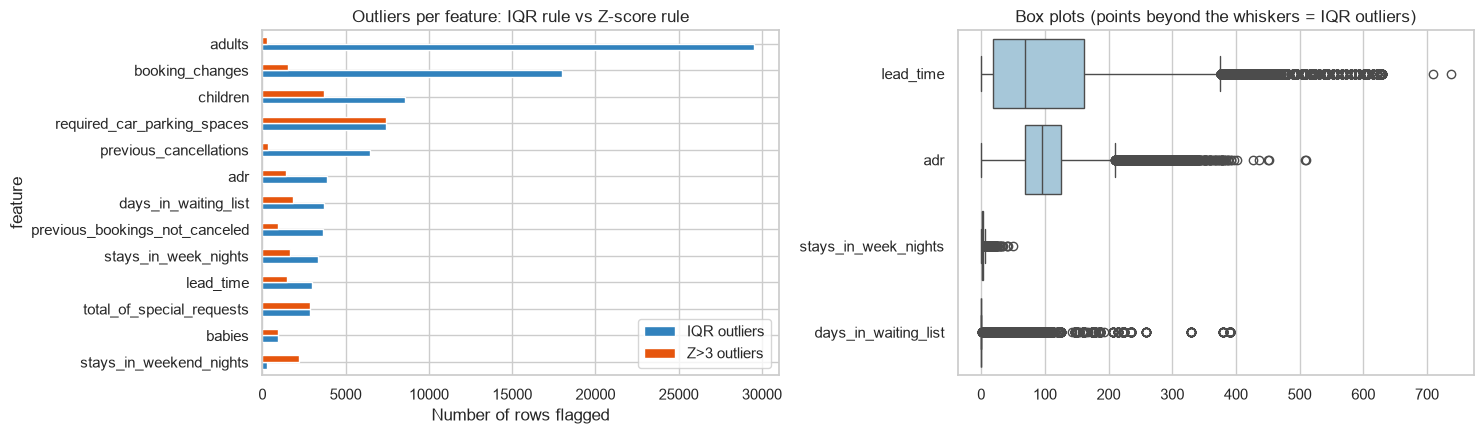

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
o = outliers[['IQR outliers', 'Z>3 outliers']].sort_values('IQR outliers', ascending=True)
o.plot(kind='barh', ax=axes[0], color=['#3182bd', '#e6550d'])
axes[0].set_title('Outliers per feature: IQR rule vs Z-score rule')
axes[0].set_xlabel('Number of rows flagged')
sns.boxplot(data=(X_out[['lead_time', 'adr', 'stays_in_week_nights', 'days_in_waiting_list']]), orient='h', ax=axes[1], color='#9ecae1')
axes[1].set_title('Box plots (points beyond the whiskers = IQR outliers)')
plt.tight_layout()
plt.savefig(f'{output_dir}/outlier_detection.png', dpi=300)
plt.show()

In [6]:
iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=42, n_jobs=-1)
iso_flag = iso.fit_predict(X_out) == -1
print(f'Isolation Forest flagged {iso_flag.sum():,} bookings (1%).')
cmp = pd.DataFrame({
    'Method': ['IQR rule (any feature)', 'Z-score > 3 (any feature)', 'Isolation Forest (1%)', 'All data'],
    'Rows flagged': [iqr_any.sum(), z_any.sum(), iso_flag.sum(), len(df)],
    '% of data': [iqr_any.mean() * 100, z_any.mean() * 100, iso_flag.mean() * 100, 100],
    'Cancellation rate of flagged rows': [df.is_canceled[iqr_any].mean(), df.is_canceled[z_any].mean(),
                                          df.is_canceled[iso_flag].mean(), df.is_canceled.mean()]}).round(3)
cmp.to_csv(f'{output_dir}/outlier_methods_comparison.csv', index=False)
display(cmp)
print('Agreement: rows flagged by BOTH IQR and Z-score:', int((iqr_any & z_any).sum()))
print('Examples of the most isolated bookings:')
display(df.loc[iso_flag, out_cols].assign(score=iso.score_samples(X_out)[iso_flag]).sort_values('score').head(5))

Isolation Forest flagged 1,193 bookings (1%).


,Method,Rows flagged,% of data,Cancellation rate of flagged rows
0,IQR rule (any feature),63855,53.566,0.350
1,Z-score > 3 (any feature),21750,18.245,0.263
2,Isolation Forest (1%),1193,1.001,0.128
3,All data,119208,100.000,0.371


Agreement: rows flagged by BOTH IQR and Z-score: 21517
Examples of the most isolated bookings:


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,score
15126,157,4,9,2,0.0,0,1,8,2,0,147.0,1,4,-0.721821
27242,82,4,10,2,2.0,0,0,1,2,0,318.0,1,3,-0.718142
15130,108,4,10,2,0.0,0,1,12,1,0,143.5,1,4,-0.713714
76715,11,2,1,1,0.0,0,5,57,3,0,67.0,1,2,-0.709908
76714,7,0,2,1,0.0,0,5,56,3,0,67.0,1,2,-0.704868


### How we handled the outliers and why
* **Removed (errors):** the 180 ghost bookings and the 2 impossible prices (negative ADR and 5,400 EUR). These cannot be real stays.
* **Kept (real rare cases):** all other flagged values. Reasons:
  1. The IQR rule flags a very large part of the data (see the printed percentage above) because many features are counts with mostly zeros (`babies`, `previous_cancellations`, `days_in_waiting_list`, `booking_changes`): every non-zero value becomes an "outlier". Deleting them would throw away a big share of the bookings.
  2. The flagged rows are **not random**: their cancellation rate differs strongly from the average (last column above). E.g. long lead times and earlier cancellations are among the *strongest* cancellation signals - removing them would remove exactly the information the model needs and would bias the test set.
  3. Our best models are **tree-based** (Decision Tree, Random Forest, XGBoost, LightGBM). Trees split on thresholds and are therefore not sensitive to extreme values.
  4. For distance/gradient based models (KNN, MLP) extreme values are softened by **standardisation** (next section).
* The Z-score rule is less aggressive than IQR, but it assumes a roughly normal distribution, which our skewed features do not have; this is another reason we used both methods only for *detection* and decided per feature.

## 4. Eliminate target leakage & engineer features (team decision)
- **Drop `reservation_status` and `reservation_status_date`**: they record what happened after the booking finished (e.g. 'Check-Out' or 'Canceled'). Using them would cause 100% target leakage.
- **New features**: total stay nights, total guests, special-requests flag, booking-changes flag, room-type-changed flag.

In [7]:
print(pd.crosstab(raw['reservation_status'], raw['is_canceled']))   # proof of leakage: status determines the target
df = df.drop(columns=['reservation_status', 'reservation_status_date'])

df['total_stay_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'].fillna(0) + df['babies']
df['has_special_requests'] = (df['total_of_special_requests'] > 0).astype(int)
df['has_booking_changes'] = (df['booking_changes'] > 0).astype(int)
df['room_type_changed'] = (df['reserved_room_type'] != df['assigned_room_type']).astype(int)

# Missing value imputation (see section 1)
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
df['agent'] = df['agent'].fillna(0)
df['company'] = df['company'].fillna(0)
print(f'Missing values remaining: {df.isnull().sum().sum()}')
print(df[['total_stay_nights', 'total_guests', 'has_special_requests', 'has_booking_changes', 'room_type_changed', 'is_canceled']]
      .groupby('has_special_requests')['is_canceled'].mean().rename('cancel rate by has_special_requests'))

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207
Missing values remaining: 0
has_special_requests
0    0.477685
1    0.217613
Name: cancel rate by has_special_requests, dtype: float64


## 5. Stratified train / test split
80% training, 20% test, preserving the cancellation proportion (`stratify=y`, `random_state=42`).

In [8]:
X = df.drop(columns=['is_canceled'])
y = df['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f'Training instances: {X_train.shape[0]:,} (Cancel rate: {y_train.mean():.2%})')
print(f'Testing instances:  {X_test.shape[0]:,} (Cancel rate: {y_test.mean():.2%})')

Training instances: 95,366 (Cancel rate: 37.08%)
Testing instances:  23,842 (Cancel rate: 37.08%)


## 6. Scaling and encoding
* **Numerical features -> `StandardScaler`** (z = (x - mean) / std, mean and std learned on the training set only). The features have very different units and ranges (lead time up to 700 days, ADR in EUR, counts 0-10, flags 0/1). Without scaling, distance-based **KNN** would be dominated by `lead_time` and `adr`, and the gradient-based **MLP** would converge slowly. Trees do not need scaling, but it does not hurt them, so one common matrix is used for all models.
* **Categorical features -> `OneHotEncoder`** (one 0/1 column per category, `handle_unknown='ignore'` so an unseen category in the test set becomes all zeros). The categories have **no natural order** (`hotel`, `meal`, `country`, `market_segment` ...), so label/ordinal encoding would invent a false order (e.g. PRT < GBR). One-hot encoding avoids this.
* `agent` and `company` are IDs stored as numbers; they were kept numeric (scaled) as in the original team pipeline - tree models can still isolate single IDs by thresholds.
* The `ColumnTransformer` is **fit only on the training data** and then applied to the test data, so no information from the test set leaks into training.

In [9]:
cat_cols = X_train.select_dtypes(exclude=['number']).columns.tolist()
num_cols = X_train.select_dtypes(include=['number']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print(f'Numerical (scaled) columns: {len(num_cols)}')
print(f'Categorical (one-hot) columns: {len(cat_cols)}')
print(f'Transformed feature matrix: {X_train_processed.shape[1]} features.')

enc = pd.DataFrame({'Categorical feature': cat_cols,
                    'Categories (= new 0/1 columns)': [len(c) for c in preprocessor.named_transformers_['cat'].categories_]})
enc.to_csv(f'{output_dir}/one_hot_encoding_summary.csv', index=False)
display(enc)

Numerical (scaled) columns: 24
Categorical (one-hot) columns: 10
Transformed feature matrix: 255 features.


,Categorical feature,Categories (= new 0/1 columns)
0,hotel,2
1,arrival_date_month,12
2,meal,5
3,country,172
4,market_segment,8
5,distribution_channel,5
6,reserved_room_type,9
7,assigned_room_type,11
8,deposit_type,3
9,customer_type,4


,mean before,std before,learned mean (scaler),learned std (scaler),mean after,std after
lead_time,103.953,106.841,103.953,106.840,-0.0,1.0
arrival_date_year,2016.157,0.707,2016.157,0.707,-0.0,1.0
arrival_date_week_number,27.122,13.605,27.122,13.605,-0.0,1.0
arrival_date_day_of_month,15.800,8.785,15.800,8.785,-0.0,1.0
stays_in_weekend_nights,0.926,0.995,0.926,0.995,0.0,1.0
stays_in_week_nights,2.497,1.899,2.497,1.899,0.0,1.0
adults,1.859,0.579,1.859,0.579,0.0,1.0
children,0.105,0.401,0.105,0.401,0.0,1.0
babies,0.008,0.100,0.008,0.100,0.0,1.0
is_repeated_guest,0.032,0.175,0.032,0.175,-0.0,1.0


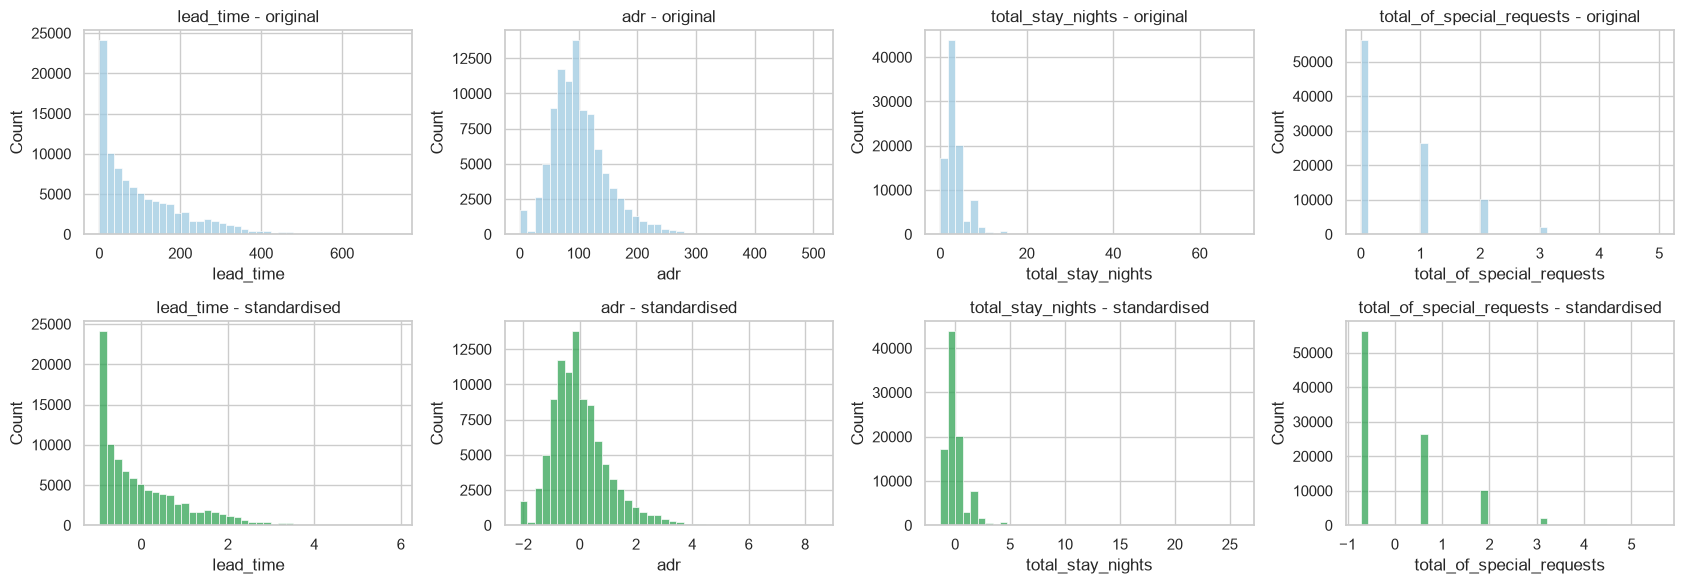

In [10]:
scaler = preprocessor.named_transformers_['num']
show = ['lead_time', 'adr', 'total_stay_nights', 'total_of_special_requests']
Xtr_s = pd.DataFrame(X_train_processed[:, :len(num_cols)], columns=num_cols)
scale_tab = pd.DataFrame({'mean before': X_train[num_cols].mean(), 'std before': X_train[num_cols].std(),
                          'learned mean (scaler)': scaler.mean_, 'learned std (scaler)': scaler.scale_,
                          'mean after': Xtr_s.mean().values, 'std after': Xtr_s.std().values}).round(3)
scale_tab.to_csv(f'{output_dir}/scaling_before_after.csv')
display(scale_tab)

fig, axes = plt.subplots(2, 4, figsize=(17, 6))
for i, c in enumerate(show):
    sns.histplot(X_train[c], bins=40, ax=axes[0, i], color='#9ecae1')
    axes[0, i].set_title(f'{c} - original')
    sns.histplot(Xtr_s[c], bins=40, ax=axes[1, i], color='#31a354')
    axes[1, i].set_title(f'{c} - standardised')
plt.tight_layout()
plt.savefig(f'{output_dir}/scaling_before_after.png', dpi=300)
plt.show()

## 7. Save processed datasets & preprocessor

In [11]:
X_train_df = pd.DataFrame(X_train_processed, columns=feature_names)
X_test_df = pd.DataFrame(X_test_processed, columns=feature_names)
X_train_df.to_parquet(f'{processed_dir}/X_train.parquet')
X_test_df.to_parquet(f'{processed_dir}/X_test.parquet')
pd.DataFrame(y_train).to_csv(f'{processed_dir}/y_train.csv', index=False)
pd.DataFrame(y_test).to_csv(f'{processed_dir}/y_test.csv', index=False)
joblib.dump(preprocessor, f'{models_dir}/preprocessor.joblib')

summary_table = pd.DataFrame({
    'Metric': ['Initial Raw Rows', 'Ghost bookings removed', 'ADR errors removed', 'Cleaned Records',
               'Training Rows (80%)', 'Testing Rows (20%)', 'Numerical features (scaled)', 'Categorical features (one-hot)', 'Total Predictors'],
    'Value': [len(raw), int(ghost_mask.sum()), len(raw) - int(ghost_mask.sum()) - len(df), len(df),
              len(X_train), len(X_test), len(num_cols), len(cat_cols), len(feature_names)]
})
summary_table.to_csv(f'{output_dir}/preprocessing_summary.csv', index=False)
print('Data preprocessing complete and artifacts saved!')
summary_table

Data preprocessing complete and artifacts saved!


,Metric,Value
0,Initial Raw Rows,119390
1,Ghost bookings removed,180
2,ADR errors removed,2
3,Cleaned Records,119208
4,Training Rows (80%),95366
5,Testing Rows (20%),23842
6,Numerical features (scaled),24
7,Categorical features (one-hot),10
8,Total Predictors,255
